# El invernadero: ATE, posterior y decisiones

**Fundamentos matemáticos de la causalidad** · Matias Moran

Este notebook acompaña la charla *Inferencia bayesiana: pensar con incertidumbre*. Usa una simulación reproducible del ejemplo del invernadero de *Statistical Rethinking* para responder tres preguntas:

1. `P(ATE > 0 | datos)`
2. `P(0.5 < ATE < 1.5 cm | datos)`
3. `P(≥5 de 10 plantas nuevas tratadas > 14 cm | datos)`

El modelo principal es lineal en centímetros, para que `β_T` sea directamente comparable con el ATE. Los datos son simulados, no reales. La semilla es `1`.

La sección 8 guarda en `figuras/` las imágenes que usa la presentación.


## 0. Librerías y configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az

RANDOM_SEED = 1

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
pd.set_option("display.precision", 3)


## 1. Simulación del invernadero

Generamos 100 plantas con el mismo mecanismo del libro:

- altura inicial `h0 ~ Normal(10, 2)`
- tratamiento `T` aleatorizado 50/50
- hongo `F ~ Bernoulli(0.5 - 0.4 T)`
- altura final `h1 = h0 + Normal(5 - 3 F, 1)`

En este DGP, el tratamiento reduce la probabilidad de hongo en 0.4 y el hongo reduce el crecimiento en 3 cm. Por eso el ATE verdadero es `3 × 0.4 = 1.2 cm`.


In [2]:
rng = np.random.default_rng(RANDOM_SEED)

N = 100
h0 = rng.normal(10, 2, N)
treatment = np.repeat([0, 1], N // 2)
fungus = rng.binomial(1, 0.5 - 0.4 * treatment)
h1 = h0 + rng.normal(5 - 3 * fungus, 1.0, N)

df = pd.DataFrame({
    "h0": h0,
    "treatment": treatment,
    "fungus": fungus,
    "h1": h1,
})
df["h0_c"] = df["h0"] - df["h0"].mean()
df.head()


,h0,treatment,fungus,h1,h0_c
0,10.691,0,0,15.859,0.838
1,11.643,0,1,14.192,1.790
2,10.661,0,1,11.596,0.808
3,7.394,0,1,11.222,-2.459
4,11.811,0,0,18.831,1.958


In [3]:
df.groupby("treatment").agg(
    n=("h1", "size"),
    h0_mean=("h0", "mean"),
    h1_mean=("h1", "mean"),
    fungus_mean=("fungus", "mean"),
).round(2)


,n,h0_mean,h1_mean,fungus_mean
treatment,,,,
0,50,9.93,13.21,0.50
1,50,9.78,14.26,0.12


La aleatorización deja los grupos razonablemente balanceados en altura inicial. La diferencia de medias de `h1` es el estimador de ATE.


## 2. El ATE

In [4]:
treated = df.loc[df["treatment"] == 1, "h1"]
control = df.loc[df["treatment"] == 0, "h1"]

ate_hat = treated.mean() - control.mean()
print(f"ATE_hat = {ate_hat:.3f} cm")


ATE_hat = 1.051 cm


In [5]:
B = 10_000
boot_rng = np.random.default_rng(123)
h1_values = df["h1"].to_numpy()
t_values = df["treatment"].to_numpy()

boot_ates = np.empty(B)
for b in range(B):
    idx = boot_rng.integers(0, N, N)
    boot_ates[b] = (
        h1_values[idx][t_values[idx] == 1].mean()
        - h1_values[idx][t_values[idx] == 0].mean()
    )

ci_95 = np.percentile(boot_ates, [2.5, 97.5])
print(f"IC 95% bootstrap = [{ci_95[0]:.3f}, {ci_95[1]:.3f}] cm")


IC 95% bootstrap = [0.132, 1.951] cm


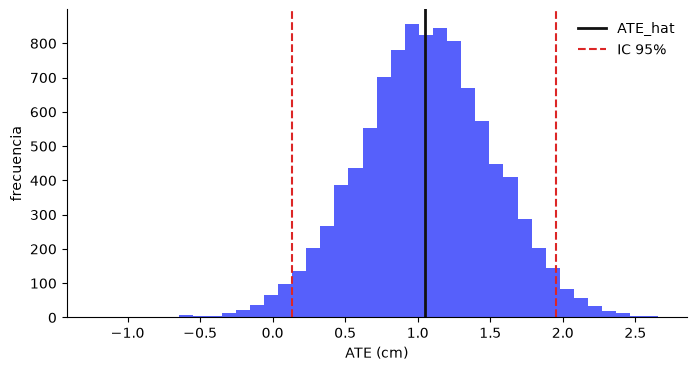

In [6]:
plt.hist(boot_ates, bins=40, color="#1e2bfa", alpha=0.75)
plt.axvline(ate_hat, color="#111111", lw=2, label="ATE_hat")
plt.axvline(ci_95[0], color="#dc2626", ls="--", label="IC 95%")
plt.axvline(ci_95[1], color="#dc2626", ls="--")
plt.xlabel("ATE (cm)")
plt.ylabel("frecuencia")
plt.legend(frameon=False)
plt.show()


El ATE es un número y el IC es frecuentista. Ninguno responde directamente:

- `P(ATE > 0 | datos)`
- `P(0.5 < ATE < 1.5 cm | datos)`
- `P(≥5 de 10 plantas nuevas > 14 cm | datos)`

Para eso pasamos a un modelo probabilístico y miramos la posterior.


## 3. Un modelo lineal en cm

Modelamos la altura final en centímetros:

$$
\begin{aligned}
h1_i &\sim \text{Normal}(\mu_i, \sigma) \\
\mu_i &= a + \beta_T T_i + \beta_H (h0_i - \overline{h0}) \\
a &\sim \text{Normal}(\overline{h1}, 5) \\
\beta_T &\sim \text{Normal}(0, 5) \\
\beta_H &\sim \text{Normal}(0, 1) \\
\sigma &\sim \text{HalfNormal}(5)
\end{aligned}
$$

`β_T` es el cambio promedio en altura final para una planta tratada, ajustando por altura inicial. Está en cm, así que es directamente comparable con el ATE. **No incluimos `F`**: es post-tratamiento y está en el camino causal.


In [7]:
with pm.Model() as model_no_f:
    a = pm.Normal("a", mu=df["h1"].mean(), sigma=5)
    bT = pm.Normal("bT", mu=0, sigma=5)
    bH = pm.Normal("bH", mu=0, sigma=1)
    sigma = pm.HalfNormal("sigma", sigma=5)

    mu = (
        a
        + bT * df["treatment"].to_numpy()
        + bH * df["h0_c"].to_numpy()
    )
    pm.Normal("h1_obs", mu=mu, sigma=sigma, observed=df["h1"].to_numpy())

    trace_no_f = pm.sample(
        draws=2000,
        tune=2000,
        chains=4,
        target_accept=0.9,
        random_seed=RANDOM_SEED,
    )


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 2 jobs)


NUTS: [a, bT, bH, sigma]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 9 seconds.


In [8]:
az.summary(
    trace_no_f,
    var_names=["a", "bT", "bH", "sigma"],
    hdi_prob=0.89,
).round(3)


,mean,sd,hdi_5.5%,hdi_94.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
a,13.133,0.229,12.761,13.489,0.003,0.002,5594.0,5574.0,1.0
bT,1.203,0.320,0.691,1.706,0.004,0.003,5449.0,5479.0,1.0
bH,0.992,0.093,0.840,1.139,0.001,0.001,7612.0,5077.0,1.0
sigma,1.623,0.119,1.432,1.801,0.001,0.002,7040.0,5265.0,1.0


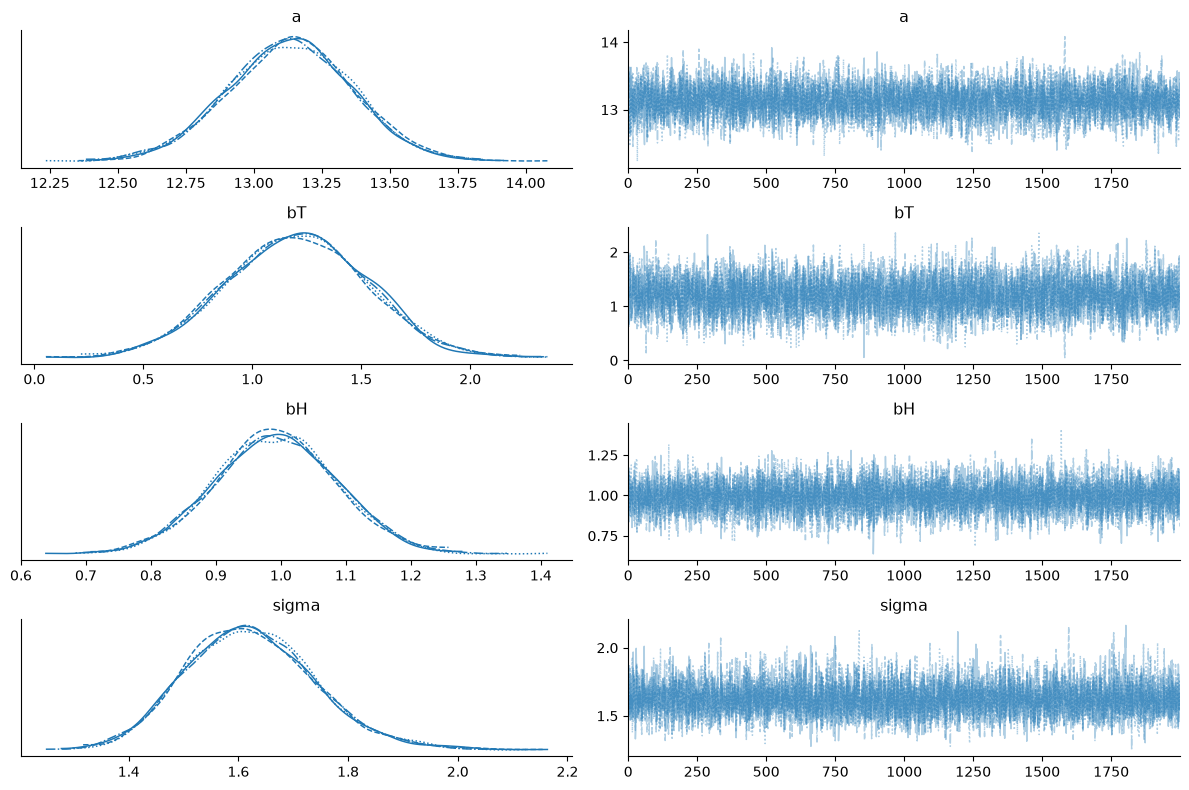

In [9]:
az.plot_trace(
    trace_no_f,
    var_names=["a", "bT", "bH", "sigma"],
    compact=True,
)
plt.tight_layout()
plt.show()


## 4. El modelo que controla por el hongo (mal)

`F` es post-tratamiento: está en el camino `T → F → H1`. Si lo incluimos, bloqueamos parte del efecto que queremos estimar. Este es el ejemplo de *post-treatment bias* del capítulo 6.


In [10]:
with pm.Model() as model_with_f:
    a = pm.Normal("a", mu=df["h1"].mean(), sigma=5)
    bT = pm.Normal("bT", mu=0, sigma=5)
    bF = pm.Normal("bF", mu=0, sigma=5)
    bH = pm.Normal("bH", mu=0, sigma=1)
    sigma = pm.HalfNormal("sigma", sigma=5)

    mu = (
        a
        + bT * df["treatment"].to_numpy()
        + bF * df["fungus"].to_numpy()
        + bH * df["h0_c"].to_numpy()
    )
    pm.Normal("h1_obs", mu=mu, sigma=sigma, observed=df["h1"].to_numpy())

    trace_with_f = pm.sample(
        draws=2000,
        tune=2000,
        chains=4,
        target_accept=0.9,
        random_seed=RANDOM_SEED,
    )


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 2 jobs)


NUTS: [a, bT, bF, bH, sigma]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 10 seconds.


In [11]:
az.summary(
    trace_with_f,
    var_names=["a", "bT", "bF", "bH", "sigma"],
    hdi_prob=0.89,
).round(3)


,mean,sd,hdi_5.5%,hdi_94.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
a,14.677,0.165,14.407,14.933,0.003,0.002,4328.0,5327.0,1.0
bT,0.028,0.197,-0.275,0.346,0.003,0.002,4724.0,5368.0,1.0
bF,-3.082,0.211,-3.428,-2.752,0.003,0.002,5129.0,5473.0,1.0
bH,0.965,0.054,0.882,1.056,0.001,0.001,7896.0,4809.0,1.0
sigma,0.923,0.066,0.816,1.026,0.001,0.001,7607.0,5722.0,1.0


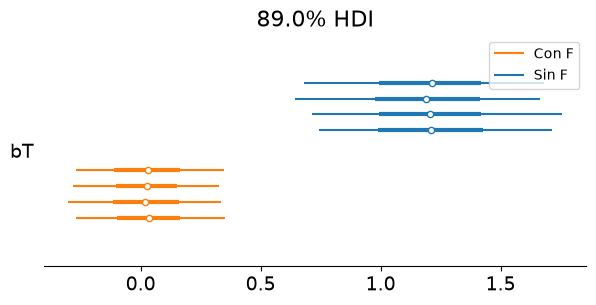

In [12]:
az.plot_forest(
    [trace_no_f, trace_with_f],
    model_names=["Sin F", "Con F"],
    var_names=["bT"],
    hdi_prob=0.89,
    figsize=(7, 3),
)
plt.show()


Sin `F`, `β_T` está cerca de 1.2 cm y el intervalo queda lejos de cero. Con `F`, `β_T` se acerca a cero y el intervalo incluye cero. El segundo modelo no es "más completo": es causalmente incorrecto para la pregunta.


## 5. Las tres preguntas causales

In [13]:
bT_samples = trace_no_f.posterior["bT"].values.flatten()
hdi_89 = az.hdi(trace_no_f, var_names=["bT"], hdi_prob=0.89)["bT"].values

p_positive = (bT_samples > 0).mean()
p_practical = ((bT_samples > 0.5) & (bT_samples < 1.5)).mean()

print(f"β_T posterior = {bT_samples.mean():.3f} cm")
print(f"HDI 89% = [{hdi_89[0]:.3f}, {hdi_89[1]:.3f}] cm")
print(f"P(ATE > 0 | datos) = {p_positive:.3f}")
print(f"P(0.5 < ATE < 1.5 cm | datos) = {p_practical:.3f}")


β_T posterior = 1.203 cm
HDI 89% = [0.691, 1.706] cm
P(ATE > 0 | datos) = 1.000
P(0.5 < ATE < 1.5 cm | datos) = 0.808


In [14]:
pd.DataFrame({
    "Pregunta": [
        "P(ATE > 0 | datos)",
        "P(0.5 < ATE < 1.5 cm | datos)",
    ],
    "Respuesta": [p_positive, p_practical],
}).round(3)


,Pregunta,Respuesta
0,P(ATE > 0 | datos),1.000
1,P(0.5 < ATE < 1.5 cm | datos),0.808


findfont: Failed to find font weight semibold, now using 700.


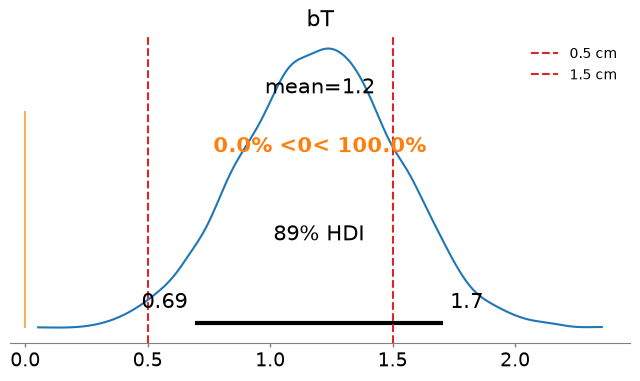

In [15]:
az.plot_posterior(
    trace_no_f,
    var_names=["bT"],
    hdi_prob=0.89,
    ref_val=0,
    figsize=(8, 4),
)
plt.axvline(0.5, color="#dc2626", ls="--", label="0.5 cm")
plt.axvline(1.5, color="#dc2626", ls="--", label="1.5 cm")
plt.legend(frameon=False)
plt.show()


## 6. La pregunta predictiva: 10 plantas nuevas

Para cada draw de la posterior:

1. sampleamos la altura inicial de 10 plantas nuevas: `h0_new ~ Normal(10, 2)`
2. calculamos `mu_new = a + bT * 1 + bH * (h0_new - mean(h0))`
3. sampleamos `h1_new ~ Normal(mu_new, sigma)`
4. contamos cuántas superan `x = 14 cm`

La pregunta es `P(≥5 de 10 plantas tratadas > 14 cm | datos)`.


In [16]:
N_NEW = 10
X_CM = 14.0

post = trace_no_f.posterior
a_s = post["a"].values.flatten()
bT_s = post["bT"].values.flatten()
bH_s = post["bH"].values.flatten()
sigma_s = post["sigma"].values.flatten()

pp_rng = np.random.default_rng(2026)
h0_new = pp_rng.normal(10, 2, size=(len(a_s), N_NEW))
h0_new_c = h0_new - df["h0"].mean()

mu_new = a_s[:, None] + bT_s[:, None] + bH_s[:, None] * h0_new_c
h1_new = pp_rng.normal(mu_new, sigma_s[:, None])
counts = (h1_new > X_CM).sum(axis=1)
p_at_least_5 = (counts >= 5).mean()

print(f"P(≥5 de 10 plantas tratadas > {X_CM:.0f} cm | datos) = {p_at_least_5:.3f}")


P(≥5 de 10 plantas tratadas > 14 cm | datos) = 0.780


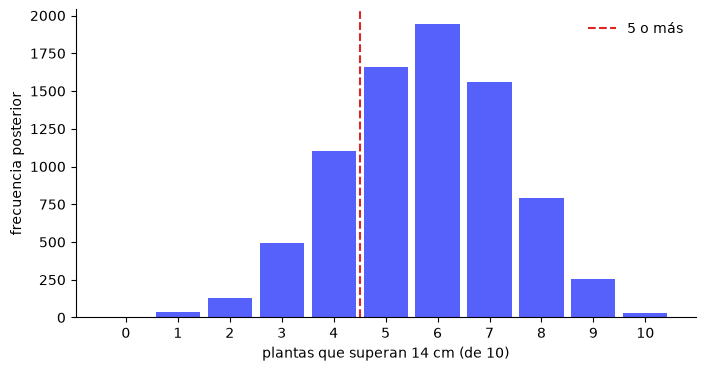

In [17]:
plt.hist(
    counts,
    bins=np.arange(-0.5, 11.5, 1),
    color="#1e2bfa",
    alpha=0.75,
    rwidth=0.85,
)
plt.axvline(4.5, color="#dc2626", ls="--", label="5 o más")
plt.xlabel("plantas que superan 14 cm (de 10)")
plt.ylabel("frecuencia posterior")
plt.xticks(range(0, 11))
plt.legend(frameon=False)
plt.show()


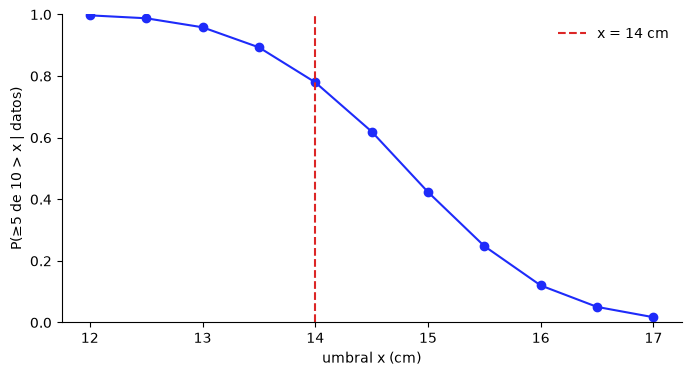

In [18]:
x_grid = np.arange(12, 17.5, 0.5)
p_grid = []

for x in x_grid:
    counts_x = (h1_new > x).sum(axis=1)
    p_grid.append((counts_x >= 5).mean())

plt.plot(x_grid, p_grid, marker="o", color="#1e2bfa")
plt.axvline(X_CM, color="#dc2626", ls="--", label="x = 14 cm")
plt.xlabel("umbral x (cm)")
plt.ylabel("P(≥5 de 10 > x | datos)")
plt.ylim(0, 1)
plt.legend(frameon=False)
plt.show()


In [19]:
from scipy.stats import norm, binom

a_mean = a_s.mean()
bT_mean = bT_s.mean()
bH_mean = bH_s.mean()
sigma_mean = sigma_s.mean()

# Plug-in: fix parameters at posterior means and h0 at its mean.
mu_plugin = a_mean + bT_mean
p_single_plugin = 1 - norm.cdf(X_CM, loc=mu_plugin, scale=sigma_mean)
p_plugin = 1 - binom.cdf(4, N_NEW, p_single_plugin)

print(f"Plug-in: P(h1 > {X_CM:.0f} cm) = {p_single_plugin:.3f}")
print(f"Plug-in: P(≥5 de 10) = {p_plugin:.3f}")
print(f"Predictiva posterior: P(≥5 de 10) = {p_at_least_5:.3f}")


Plug-in: P(h1 > 14 cm) = 0.582
Plug-in: P(≥5 de 10) = 0.802
Predictiva posterior: P(≥5 de 10) = 0.780


La predictiva posterior no es solo "el modelo con ruido": integra la incertidumbre en los parámetros y en la altura inicial de las plantas nuevas. Por eso puede diferir del plug-in que fija los parámetros en su media.


## 7. Chequeo predictivo posterior

Sampling: [h1_obs]


Output()

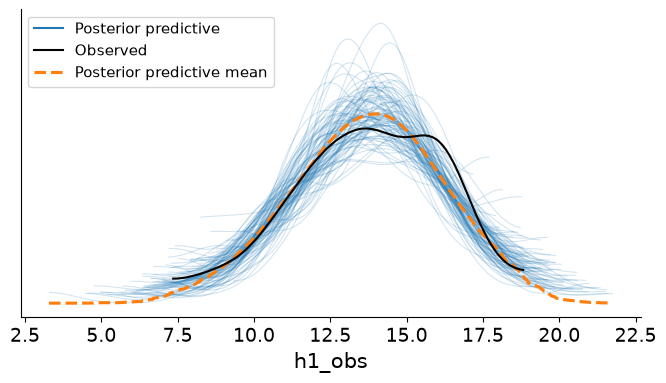

In [20]:
with model_no_f:
    ppc = pm.sample_posterior_predictive(trace_no_f, random_seed=RANDOM_SEED)

az.plot_ppc(ppc, num_pp_samples=100)
plt.show()


## 8. Figuras para la presentación

Estas celdas guardan en `figuras/` las imágenes que usa la presentación y dejan reproducidos los números de las slides. Primero el ejemplo de los chips (prior, likelihood, posterior y predictiva) y las figuras frecuentistas; después las figuras del invernadero. Se pueden correr después de las secciones 5 y 6.


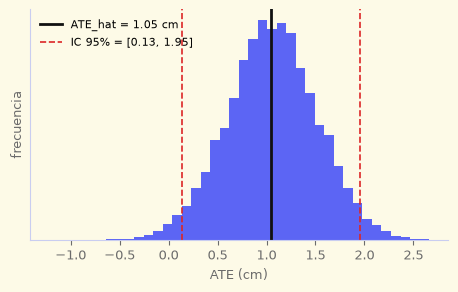

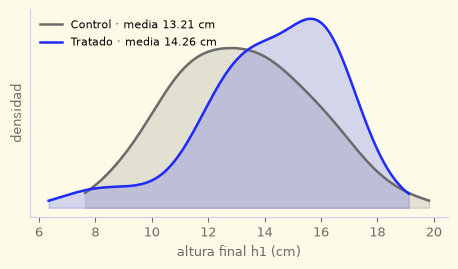

Posterior Beta(7, 4)
  mediana = 0.645
  IC 95% = [0.348, 0.878]
  P(p > 0.5 | datos) = 0.828
  P(p > 0.6 | datos) = 0.618


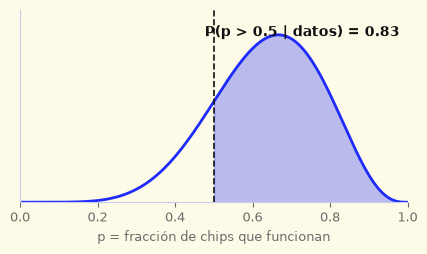

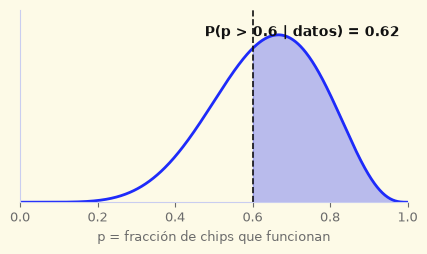

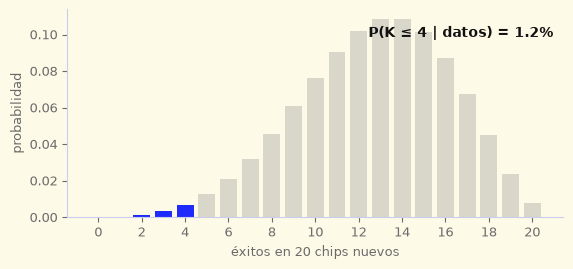

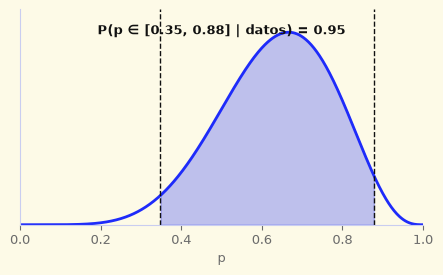

MLE = 0.667
IC 95% exacto = [0.299, 0.925]
valor p (una cola) = 0.254
valor p (dos colas) = 0.508


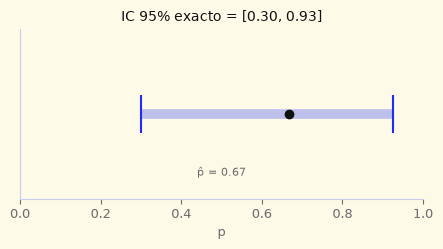

In [21]:
from pathlib import Path

from scipy.stats import beta as beta_dist
from scipy.stats import betabinom, binomtest, gaussian_kde

FIG_DIR = Path("figuras")
FIG_DIR.mkdir(exist_ok=True)

BG = "#fdfae7"
PRIMARY = "#1e2bfa"
TEXT = "#111111"
MUTED = "#6b6b6b"
RED = "#dc2626"
LIGHT = "#d9d7c9"

plt.rcParams.update({
    "figure.facecolor": BG,
    "axes.facecolor": BG,
    "savefig.facecolor": BG,
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.labelcolor": MUTED,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.edgecolor": "#c9cdf0",
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
})


def save_presentation_figure(fig, filename):
    """Save one deck figure and show it in the notebook."""
    fig.savefig(FIG_DIR / filename, dpi=220, bbox_inches="tight", facecolor=BG)
    plt.show()


# Frequentist figures
fig, ax = plt.subplots(figsize=(5.4, 3.0))
ax.hist(boot_ates, bins=40, color=PRIMARY, alpha=0.72, edgecolor="none")
ax.axvline(ate_hat, color=TEXT, lw=2, label=f"ATE_hat = {ate_hat:.2f} cm")
ax.axvline(ci_95[0], color=RED, ls="--", lw=1.2)
ax.axvline(ci_95[1], color=RED, ls="--", lw=1.2, label=f"IC 95% = [{ci_95[0]:.2f}, {ci_95[1]:.2f}]")
ax.set_xlabel("ATE (cm)")
ax.set_ylabel("frecuencia")
ax.set_yticks([])
ax.legend(loc="upper left", fontsize=8)
save_presentation_figure(fig, "frecuentista_bootstrap.png")

fig, ax = plt.subplots(figsize=(5.4, 2.7))
for values, label, color in [
    (control, "Control", MUTED),
    (treated, "Tratado", PRIMARY),
]:
    kde = gaussian_kde(values)
    grid = np.linspace(values.min() - 1, values.max() + 1, 300)
    ax.fill_between(grid, kde(grid), color=color, alpha=0.18)
    ax.plot(grid, kde(grid), color=color, lw=1.8, label=f"{label} · media {values.mean():.2f} cm")
ax.set_xlabel("altura final h1 (cm)")
ax.set_ylabel("densidad")
ax.set_yticks([])
ax.legend(loc="upper left", fontsize=8)
save_presentation_figure(fig, "frecuentista_grupos.png")

# Microchip posterior: flat prior + 6 successes / 3 failures -> Beta(7, 4)
alpha_post, beta_post = 7, 4
x_grid = np.linspace(0, 1, 600)
dens = beta_dist.pdf(x_grid, alpha_post, beta_post)
p_gt_05 = 1 - beta_dist.cdf(0.5, alpha_post, beta_post)
p_gt_06 = 1 - beta_dist.cdf(0.6, alpha_post, beta_post)
hdi_95 = beta_dist.ppf([0.025, 0.975], alpha_post, beta_post)

print(f"Posterior Beta({alpha_post}, {beta_post})")
print(f"  mediana = {beta_dist.median(alpha_post, beta_post):.3f}")
print(f"  IC 95% = [{hdi_95[0]:.3f}, {hdi_95[1]:.3f}]")
print(f"  P(p > 0.5 | datos) = {p_gt_05:.3f}")
print(f"  P(p > 0.6 | datos) = {p_gt_06:.3f}")


def plot_beta_area(threshold, filename, probability):
    fig, ax = plt.subplots(figsize=(5.0, 2.5))
    mask = x_grid > threshold
    ax.plot(x_grid, dens, color=PRIMARY, lw=2)
    ax.fill_between(x_grid, dens, where=mask, color=PRIMARY, alpha=0.30)
    ax.axvline(threshold, color=TEXT, lw=1.2, ls="--")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, dens.max() * 1.15)
    ax.set_yticks([])
    ax.set_xlabel("p = fracción de chips que funcionan")
    ax.text(
        0.98, 0.92,
        f"P(p > {threshold:.1f} | datos) = {probability:.2f}",
        transform=ax.transAxes, ha="right", va="top",
        fontsize=10, color=TEXT, fontweight="bold",
    )
    save_presentation_figure(fig, filename)


plot_beta_area(0.5, "microchip_beta_gt_05.png", p_gt_05)
plot_beta_area(0.6, "microchip_beta_gt_06.png", p_gt_06)

pp_20 = betabinom.pmf(np.arange(21), 20, alpha_post, beta_post)
p_le_4 = betabinom.cdf(4, 20, alpha_post, beta_post)
fig, ax = plt.subplots(figsize=(6.4, 2.7))
colors = [PRIMARY if k <= 4 else LIGHT for k in range(21)]
ax.bar(range(21), pp_20, color=colors, width=0.78)
ax.set_xlabel("éxitos en 20 chips nuevos")
ax.set_ylabel("probabilidad")
ax.set_xticks(range(0, 21, 2))
ax.text(
    0.98, 0.92,
    f"P(K ≤ 4 | datos) = {p_le_4 * 100:.1f}%",
    transform=ax.transAxes, ha="right", va="top",
    fontsize=10, color=TEXT, fontweight="bold",
)
save_presentation_figure(fig, "microchip_pp_20.png")

# Credible vs confidence
fig, ax = plt.subplots(figsize=(5.2, 2.8))
mask = (x_grid >= hdi_95[0]) & (x_grid <= hdi_95[1])
ax.plot(x_grid, dens, color=PRIMARY, lw=2)
ax.fill_between(x_grid, dens, where=mask, color=PRIMARY, alpha=0.28)
ax.axvline(hdi_95[0], color=TEXT, lw=1, ls="--")
ax.axvline(hdi_95[1], color=TEXT, lw=1, ls="--")
ax.set_xlim(0, 1)
ax.set_ylim(0, dens.max() * 1.12)
ax.set_yticks([])
ax.set_xlabel("p")
ax.text(
    0.5, 0.93,
    f"P(p ∈ [{hdi_95[0]:.2f}, {hdi_95[1]:.2f}] | datos) = 0.95",
    transform=ax.transAxes, ha="center", va="top",
    fontsize=9, color=TEXT, fontweight="bold",
)
save_presentation_figure(fig, "credible_beta.png")

ci_exact = binomtest(6, 9).proportion_ci(confidence_level=0.95, method="exact")
p_hat = 6 / 9
test_one = binomtest(6, 9, p=0.5, alternative="greater")
test_two = binomtest(6, 9, p=0.5, alternative="two-sided")

print(f"MLE = {p_hat:.3f}")
print(f"IC 95% exacto = [{ci_exact.low:.3f}, {ci_exact.high:.3f}]")
print(f"valor p (una cola) = {test_one.pvalue:.3f}")
print(f"valor p (dos colas) = {test_two.pvalue:.3f}")
fig, ax = plt.subplots(figsize=(5.2, 2.2))
ax.hlines(0, ci_exact.low, ci_exact.high, color=PRIMARY, lw=7, alpha=0.28)
ax.vlines([ci_exact.low, ci_exact.high], -0.16, 0.16, color=PRIMARY, lw=1.5)
ax.plot(p_hat, 0, "o", color=TEXT, ms=6, zorder=3)
ax.set_xlim(0, 1)
ax.set_ylim(-0.7, 0.7)
ax.set_yticks([])
ax.set_xlabel("p")
ax.set_title(f"IC 95% exacto = [{ci_exact.low:.2f}, {ci_exact.high:.2f}]", fontsize=10, color=TEXT, pad=6)
ax.text(0.5, 0.12, f"p̂ = {p_hat:.2f}", transform=ax.transAxes, ha="center", va="bottom", fontsize=8, color=MUTED)
save_presentation_figure(fig, "confidence_interval.png")


### 8.1 Curvas del ejemplo y frecuentismo en los 9 chips

Graficamos las tres funciones del ejemplo beta-binomial y las dos vistas frecuentistas del caso de los microchips: bootstrap de `p̂` y distribución nula bajo `H0: p = 0.5`.


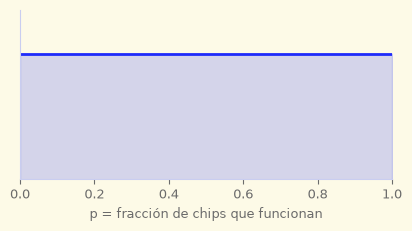

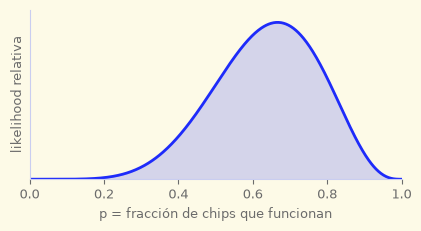

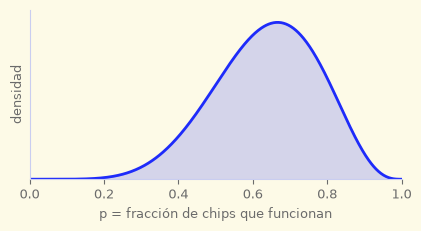

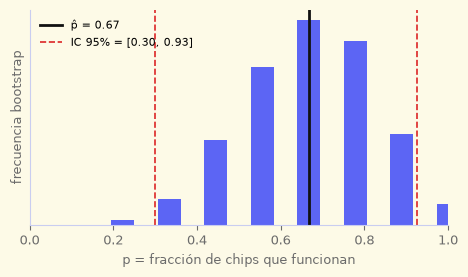

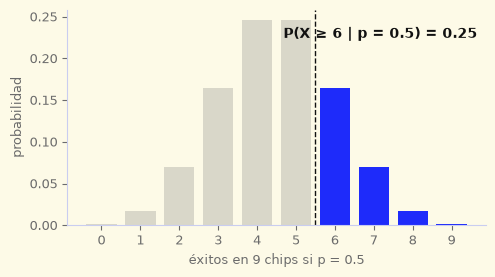

In [22]:
from scipy.stats import binom

# Curves for the beta-binomial slide
p_grid = np.linspace(0, 1, 600)

fig, ax = plt.subplots(figsize=(4.8, 2.2))
flat_prior = beta_dist.pdf(p_grid, 1, 1)
ax.plot(p_grid, flat_prior, color=PRIMARY, lw=2)
ax.fill_between(p_grid, flat_prior, color=PRIMARY, alpha=0.18)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.35)
ax.set_yticks([])
ax.set_xlabel("p = fracción de chips que funcionan")
save_presentation_figure(fig, "beta_prior.png")

fig, ax = plt.subplots(figsize=(4.8, 2.2))
likelihood = p_grid**6 * (1 - p_grid)**3
likelihood = likelihood / likelihood.max()
ax.plot(p_grid, likelihood, color=PRIMARY, lw=2)
ax.fill_between(p_grid, likelihood, color=PRIMARY, alpha=0.18)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.08)
ax.set_yticks([])
ax.set_xlabel("p = fracción de chips que funcionan")
ax.set_ylabel("likelihood relativa")
save_presentation_figure(fig, "beta_likelihood.png")

fig, ax = plt.subplots(figsize=(4.8, 2.2))
posterior = beta_dist.pdf(p_grid, alpha_post, beta_post)
ax.plot(p_grid, posterior, color=PRIMARY, lw=2)
ax.fill_between(p_grid, posterior, color=PRIMARY, alpha=0.18)
ax.set_xlim(0, 1)
ax.set_ylim(0, posterior.max() * 1.08)
ax.set_yticks([])
ax.set_xlabel("p = fracción de chips que funcionan")
ax.set_ylabel("densidad")
save_presentation_figure(fig, "beta_posterior.png")

# Frequentist view of the 9-chip example
micro_rng = np.random.default_rng(7)
boot_p = micro_rng.binomial(9, p_hat, 10_000) / 9
boot_values, boot_counts = np.unique(boot_p, return_counts=True)

fig, ax = plt.subplots(figsize=(5.4, 2.8))
ax.bar(boot_values, boot_counts / boot_counts.sum(), width=0.055, color=PRIMARY, alpha=0.72)
ax.axvline(p_hat, color=TEXT, lw=2, label=f"p̂ = {p_hat:.2f}")
ax.axvline(ci_exact.low, color=RED, ls="--", lw=1.2)
ax.axvline(ci_exact.high, color=RED, ls="--", lw=1.2, label=f"IC 95% = [{ci_exact.low:.2f}, {ci_exact.high:.2f}]")
ax.set_xlim(0, 1)
ax.set_xlabel("p = fracción de chips que funcionan")
ax.set_ylabel("frecuencia bootstrap")
ax.set_yticks([])
ax.legend(loc="upper left", fontsize=8)
save_presentation_figure(fig, "microchip_frecuentista_bootstrap.png")

fig, ax = plt.subplots(figsize=(5.4, 2.8))
null_x = np.arange(10)
null_pmf = binom.pmf(null_x, 9, 0.5)
null_colors = [PRIMARY if k >= 6 else LIGHT for k in null_x]
ax.bar(null_x, null_pmf, color=null_colors, width=0.78)
ax.axvline(5.5, color=TEXT, lw=1, ls="--")
ax.set_xticks(null_x)
ax.set_xlabel("éxitos en 9 chips si p = 0.5")
ax.set_ylabel("probabilidad")
ax.text(
    0.98, 0.92,
    f"P(X ≥ 6 | p = 0.5) = {test_one.pvalue:.2f}",
    transform=ax.transAxes, ha="right", va="top",
    fontsize=10, color=TEXT, fontweight="bold",
)
save_presentation_figure(fig, "microchip_frecuentista_test.png")


### 8.2 Figuras del invernadero

Las siguientes figuras usan la posterior del modelo sin `F` y la predictiva posterior de 10 plantas nuevas.


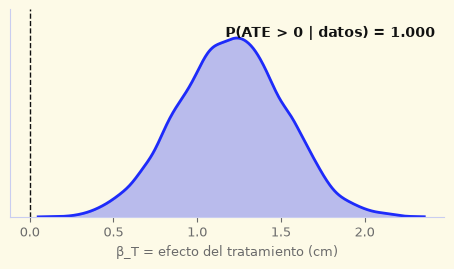

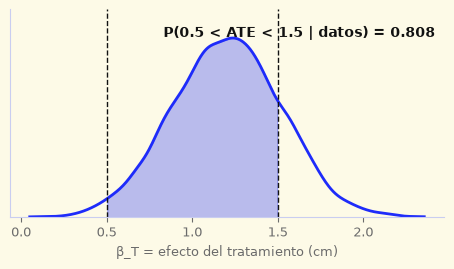

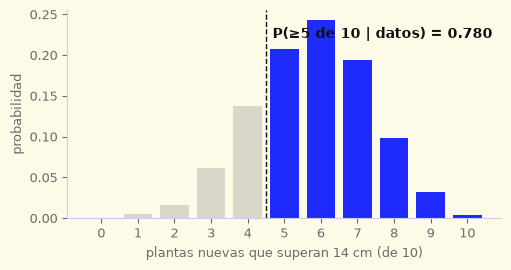

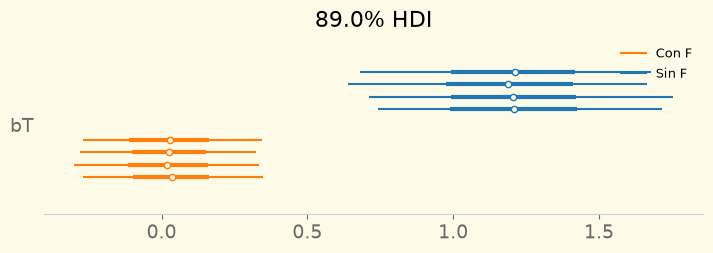

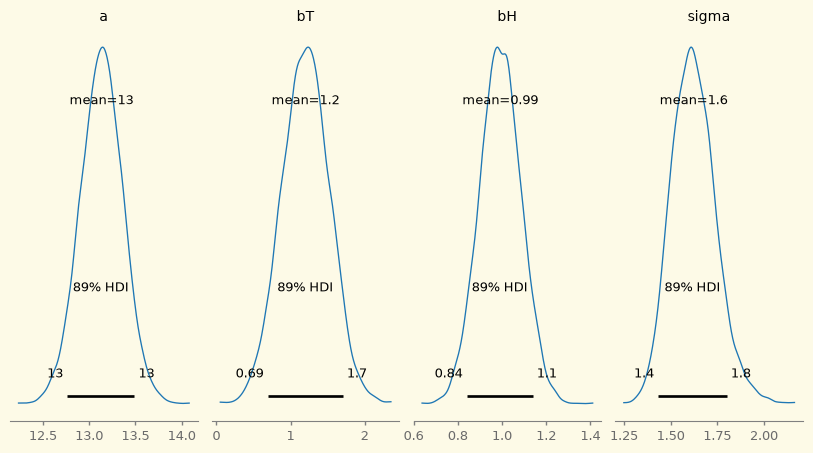

In [23]:
# Causal posterior figures
def plot_causal_area(filename, probability, label, lo=None, hi=None):
    kde = gaussian_kde(bT_samples)
    grid = np.linspace(bT_samples.min(), bT_samples.max(), 500)
    y = kde(grid)
    fig, ax = plt.subplots(figsize=(5.6, 2.7))
    ax.plot(grid, y, color=PRIMARY, lw=2)
    if hi is None:
        mask = grid > lo
        ax.axvline(lo, color=TEXT, lw=1, ls="--")
    else:
        mask = (grid > lo) & (grid < hi)
        ax.axvline(lo, color=TEXT, lw=1, ls="--")
        ax.axvline(hi, color=TEXT, lw=1, ls="--")
    ax.fill_between(grid, y, where=mask, color=PRIMARY, alpha=0.30)
    ax.set_xlabel("β_T = efecto del tratamiento (cm)")
    ax.set_yticks([])
    ax.set_ylim(0, y.max() * 1.16)
    ax.text(
        0.98, 0.92,
        f"{label} = {probability:.3f}",
        transform=ax.transAxes, ha="right", va="top",
        fontsize=10, color=TEXT, fontweight="bold",
    )
    save_presentation_figure(fig, filename)


plot_causal_area("posterior_ate_gt_0.png", p_positive, "P(ATE > 0 | datos)", lo=0)
plot_causal_area("posterior_ate_practical.png", p_practical, "P(0.5 < ATE < 1.5 | datos)", lo=0.5, hi=1.5)

fig, ax = plt.subplots(figsize=(5.6, 2.7))
freq = np.bincount(counts, minlength=11) / len(counts)
colors = [PRIMARY if k >= 5 else LIGHT for k in range(11)]
ax.bar(range(11), freq, color=colors, width=0.78)
ax.axvline(4.5, color=TEXT, lw=1, ls="--")
ax.set_xlabel("plantas nuevas que superan 14 cm (de 10)")
ax.set_ylabel("probabilidad")
ax.set_xticks(range(0, 11))
ax.text(
    0.98, 0.92,
    f"P(≥5 de 10 | datos) = {p_at_least_5:.3f}",
    transform=ax.transAxes, ha="right", va="top",
    fontsize=10, color=TEXT, fontweight="bold",
)
save_presentation_figure(fig, "posterior_pp_at_least_5.png")

# Forest plot: with and without the post-treatment variable
az.plot_forest(
    [trace_no_f, trace_with_f],
    model_names=["Sin F", "Con F"],
    var_names=["bT"],
    hdi_prob=0.89,
    figsize=(7.2, 2.6),
)
plt.tight_layout()
save_presentation_figure(plt.gcf(), "forest_bT.png")

# Posterior marginals, without the MCMC chains
az.plot_posterior(
    trace_no_f,
    var_names=["a", "bT", "bH", "sigma"],
    hdi_prob=0.89,
    figsize=(8.2, 4.6),
    textsize=9,
)
plt.tight_layout()
save_presentation_figure(plt.gcf(), "trace_marginals.png")


## 9. Conclusiones


- El ATE es un número: `ATE_hat = 1.05 cm`, IC 95% bootstrap `[0.13, 1.95]`.
- El modelo causal sin `F` devuelve `β_T = 1.20 cm [0.69, 1.71]` (89% HDI): el tratamiento hace crecer.
- El modelo con `F` devuelve `β_T = 0.03 cm [-0.28, 0.34]`: controlar una variable post-tratamiento borra el efecto.
- La posterior responde `P(ATE > 0) = 1.000` (en esta simulación) y `P(0.5 < ATE < 1.5) = 0.81`.
- La predictiva responde `P(≥5 de 10 plantas nuevas > 14 cm) = 0.78`.
- Bayes no elige el DAG: el DAG decide qué modelo es causal; la posterior cuantifica la incertidumbre.


In [24]:
hdi_with_f = az.hdi(trace_with_f, var_names=["bT"], hdi_prob=0.89)["bT"].values
bT_with_f_samples = trace_with_f.posterior["bT"].values.flatten()

summary = pd.DataFrame({
    "Cantidad": [
        "ATE_hat (cm)",
        "IC 95% bootstrap",
        "β_T sin F (cm)",
        "β_T con F (cm)",
        "P(ATE > 0)",
        "P(0.5 < ATE < 1.5)",
        "P(≥5 de 10 > 14 cm)",
    ],
    "Valor": [
        f"{ate_hat:.2f}",
        f"[{ci_95[0]:.2f}, {ci_95[1]:.2f}]",
        f"{bT_samples.mean():.2f} [{hdi_89[0]:.2f}, {hdi_89[1]:.2f}]",
        f"{bT_with_f_samples.mean():.2f} [{hdi_with_f[0]:.2f}, {hdi_with_f[1]:.2f}]",
        f"{p_positive:.3f}",
        f"{p_practical:.3f}",
        f"{p_at_least_5:.3f}",
    ],
})
summary


,Cantidad,Valor
0,ATE_hat (cm),1.05
1,IC 95% bootstrap,"[0.13, 1.95]"
2,β_T sin F (cm),"1.20 [0.69, 1.71]"
3,β_T con F (cm),"0.03 [-0.28, 0.35]"
4,P(ATE > 0),1.000
5,P(0.5 < ATE < 1.5),0.808
6,P(≥5 de 10 > 14 cm),0.780
